In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
import pandas as pd

base = "/content/drive/MyDrive/Brock_University/pidgindataset2026October/"

df = pd.read_csv(base + "root/Metadata1.csv")

In [ ]:
df["audio_length"] = (
    df["audio_length"]
    .astype(str)
    .str.replace("secs", "", regex=False)
    .str.strip()
    .astype(float)
)

In [26]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio,audio,file_exists,text,reference,sample_id
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,54.947548,0.319377,/content/drive/MyDrive/Brock_University/pidgin...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,53.953575,0.334655,/content/drive/MyDrive/Brock_University/pidgin...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,57.647476,0.335672,/content/drive/MyDrive/Brock_University/pidgin...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,49.890247,0.308394,/content/drive/MyDrive/Brock_University/pidgin...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,50.834831,0.307166,/content/drive/MyDrive/Brock_University/pidgin...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166


In [27]:
df.describe()

,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio
count,10218.000000,10218.0,10218.0,10218.000000,10218.000000,10218.000000
mean,27.826377,16000.0,1.0,2.363408,32.039383,0.187849
std,12.653020,0.0,0.0,0.492410,10.505199,0.111876
min,2.150000,16000.0,1.0,0.132050,5.822312,0.000000
25%,19.310000,16000.0,1.0,2.029071,25.182662,0.120457
50%,25.310000,16000.0,1.0,2.346576,30.804038,0.187444
75%,34.025000,16000.0,1.0,2.685537,37.089207,0.259174
max,124.390000,16000.0,1.0,14.694917,65.283104,0.971912


In [28]:
total_hours = df["audio_length"].sum() / 3600

In [29]:
print(total_hours)

78.98053333333333


In [30]:
total_utterances = len(df)
print(total_utterances)

10218


In [31]:
num_speakers = df["speaker_id"].nunique()
print(num_speakers)

21


In [32]:
num_english_words = df["english_translation"].apply(
    lambda x: len(str(x).split())
).sum()

print(num_english_words)

660891


In [33]:
num_pidgin_words = df["pidgin_transcription"].apply(
    lambda x: len(str(x).split())
).sum()
print(num_pidgin_words)

659853


In [34]:
stats = {
    "Total Hours": round(total_hours, 2),
    "Total Utterances": total_utterances,
    "Number of Speakers": num_speakers,
    "English Words": num_english_words,
    "Pidgin Words": num_pidgin_words,
}

for k, v in stats.items():
    print(f"{k}: {v}")

Total Hours: 78.98
Total Utterances: 10218
Number of Speakers: 21
English Words: 660891
Pidgin Words: 659853


In [35]:
features = ["speech_rate", "signal_to_noise_ratio", "silence_ratio"]

stats = df[features].describe()
print(stats)

        speech_rate  signal_to_noise_ratio  silence_ratio
count  10218.000000           10218.000000   10218.000000
mean       2.363408              32.039383       0.187849
std        0.492410              10.505199       0.111876
min        0.132050               5.822312       0.000000
25%        2.029071              25.182662       0.120457
50%        2.346576              30.804038       0.187444
75%        2.685537              37.089207       0.259174
max       14.694917              65.283104       0.971912


In [36]:
summary = {
    "Speech Rate (words/sec)": {
        "mean": df["speech_rate"].mean(),
        "std": df["speech_rate"].std(),
        "min": df["speech_rate"].min(),
        "max": df["speech_rate"].max()
    },
    "SNR (dB)": {
        "mean": df["signal_to_noise_ratio"].mean(),
        "std": df["signal_to_noise_ratio"].std(),
        "min": df["signal_to_noise_ratio"].min(),
        "max": df["signal_to_noise_ratio"].max()
    },
    "Silence Ratio": {
        "mean": df["silence_ratio"].mean(),
        "std": df["silence_ratio"].std(),
        "min": df["silence_ratio"].min(),
        "max": df["silence_ratio"].max()
    }
}

for k, v in summary.items():
    print(f"\n{k}")
    for key, val in v.items():
        print(f"{key}: {round(val, 3)}")


Speech Rate (words/sec)
mean: 2.363
std: 0.492
min: 0.132
max: 14.695

SNR (dB)
mean: 32.039
std: 10.505
min: 5.822
max: 65.283

Silence Ratio
mean: 0.188
std: 0.112
min: 0.0
max: 0.972


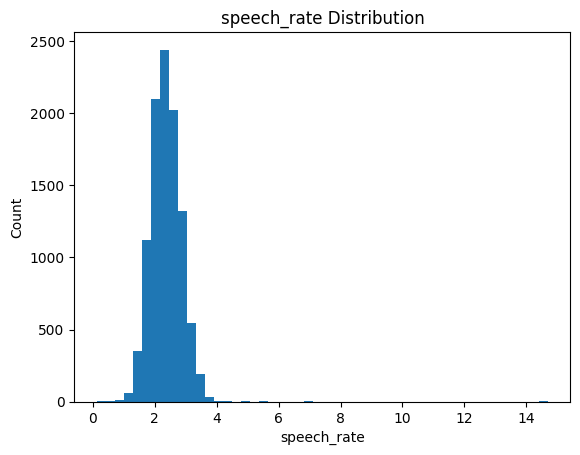

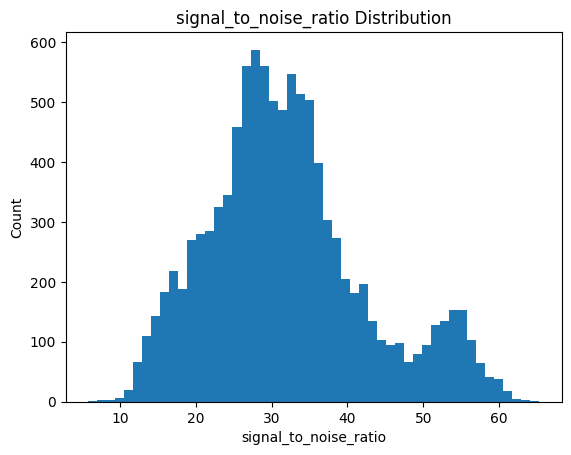

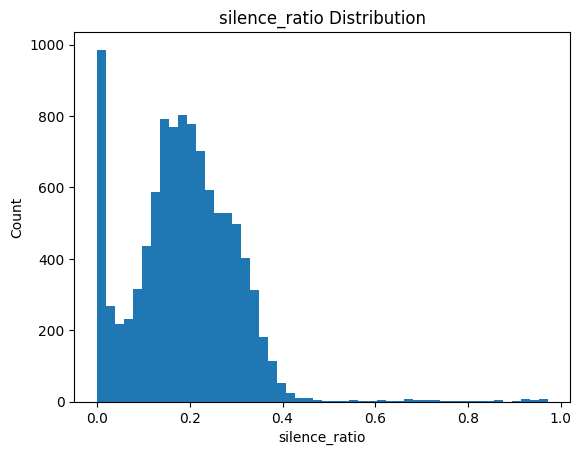

In [37]:
import matplotlib.pyplot as plt

for col in features:
    plt.figure()
    plt.hist(df[col].dropna(), bins=50)
    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [38]:
corr = df[features].corr()
print(corr)

                       speech_rate  signal_to_noise_ratio  silence_ratio
speech_rate               1.000000              -0.192559      -0.359004
signal_to_noise_ratio    -0.192559               1.000000       0.689541
silence_ratio            -0.359004               0.689541       1.000000


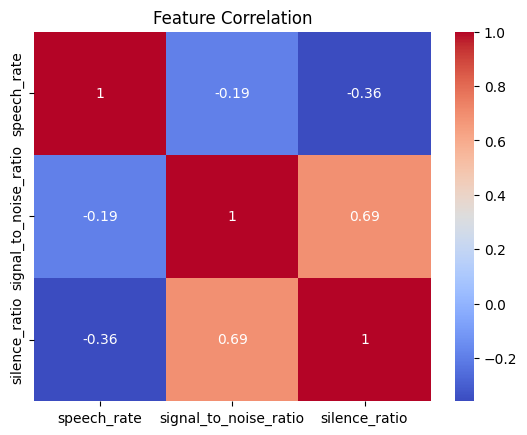

In [39]:
import seaborn as sns

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

In [40]:
speaker_stats = df.groupby("speaker_id")[features].mean()
print(speaker_stats)

            speech_rate  signal_to_noise_ratio  silence_ratio
speaker_id                                                   
Speaker_1      2.328434              51.653742       0.301022
Speaker_10     2.612046              32.513051       0.172558
Speaker_11     1.966274              26.718472       0.147160
Speaker_12     2.186288              34.424352       0.226893
Speaker_13     2.532368              31.436900       0.202822
Speaker_14     2.373104              26.521641       0.167937
Speaker_15     2.106668              33.642324       0.239321
Speaker_16     2.491369              30.492227       0.224019
Speaker_17     2.188390              19.117430       0.042287
Speaker_18     2.559090              26.369400       0.126246
Speaker_19     2.153747              30.808967       0.178760
Speaker_2      2.450865              33.911873       0.176436
Speaker_20     2.394727              28.690017       0.115450
Speaker_21     1.942061              33.891269       0.353349
Speaker_

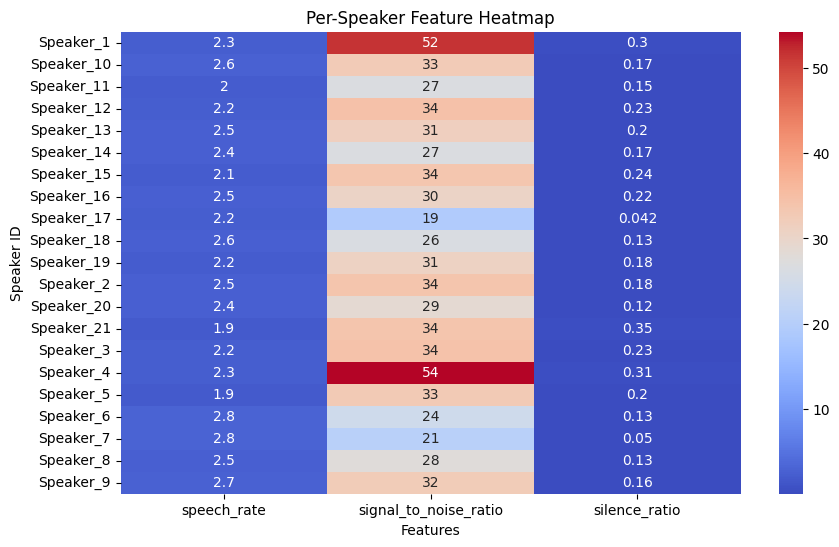

In [41]:
import seaborn as sns

plt.figure(figsize=(10,6))
sns.heatmap(speaker_stats, annot=True, cmap="coolwarm")

plt.title("Per-Speaker Feature Heatmap")
plt.xlabel("Features")
plt.ylabel("Speaker ID")

plt.show()

In [42]:
df["medical_term_count"] = df["medical_terms_pidgen"].apply(len)

print(df["medical_term_count"].describe())

count    10218.000000
mean        94.048346
std         63.820586
min          2.000000
25%         47.000000
50%         84.000000
75%        128.000000
max        494.000000
Name: medical_term_count, dtype: float64


In [43]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio,audio,file_exists,text,reference,sample_id,medical_term_count
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,54.947548,0.319377,/content/drive/MyDrive/Brock_University/pidgin...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227,74
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,53.953575,0.334655,/content/drive/MyDrive/Brock_University/pidgin...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2,106
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,57.647476,0.335672,/content/drive/MyDrive/Brock_University/pidgin...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4,85
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,49.890247,0.308394,/content/drive/MyDrive/Brock_University/pidgin...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366,158
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,50.834831,0.307166,/content/drive/MyDrive/Brock_University/pidgin...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166,254


In [44]:
import ast
from collections import Counter

In [45]:
import re
import ast
import pandas as pd

def parse_terms(x):
    if isinstance(x, list):
        return x
    if pd.isna(x):
        return []
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]
    return []

def clean_medical_terms_safe(x):
    terms = parse_terms(x)

    cleaned = []
    seen = set()

    for term in terms:
        term = str(term).lower().strip()

        # convert hyphen/slash/underscore to spaces
        term = re.sub(r"[-_/]", " ", term)

        # remove other punctuation
        term = re.sub(r"[^a-z\s]", " ", term)

        # collapse spaces
        words = re.sub(r"\s+", " ", term).strip().split()

        for word in words:
            if len(word) < 2:
                continue

            if word not in seen:
                seen.add(word)
                cleaned.append(word)

    return cleaned

df["medical_terms_clean"] = df["medical_terms_pidgen"].apply(clean_medical_terms_safe)

In [46]:
df["medical_terms_clean"] = df["medical_terms_pidgen"].apply(clean_medical_terms_safe)

In [47]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio,audio,file_exists,text,reference,sample_id,medical_term_count,medical_terms_clean
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,54.947548,0.319377,/content/drive/MyDrive/Brock_University/pidgin...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227,74,"[exercise, everytime, after, two, day, normall..."
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,53.953575,0.334655,/content/drive/MyDrive/Brock_University/pidgin...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2,106,"[daughter, wake, up, vomited, pain, hot, parac..."
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,57.647476,0.335672,/content/drive/MyDrive/Brock_University/pidgin...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4,85,"[reasons, removed, important, part, of, the, b..."
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,49.890247,0.308394,/content/drive/MyDrive/Brock_University/pidgin...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366,158,"[thirty, one, years, woman, not, head, injury,..."
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,50.834831,0.307166,/content/drive/MyDrive/Brock_University/pidgin...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166,254,"[forty, five, years, old, man, platelet, count..."


In [48]:
all_terms = [term for terms in df["medical_terms_pidgen"] for term in terms]

term_counts = Counter(all_terms)

print("Total medical term mentions:", len(all_terms))
print("Unique medical terms:", len(term_counts))

Total medical term mentions: 960986
Unique medical terms: 31


In [49]:
df["medical_term_count"] = df["medical_terms_pidgen"].apply(len)

print(df["medical_term_count"].describe())

count    10218.000000
mean        94.048346
std         63.820586
min          2.000000
25%         47.000000
50%         84.000000
75%        128.000000
max        494.000000
Name: medical_term_count, dtype: float64


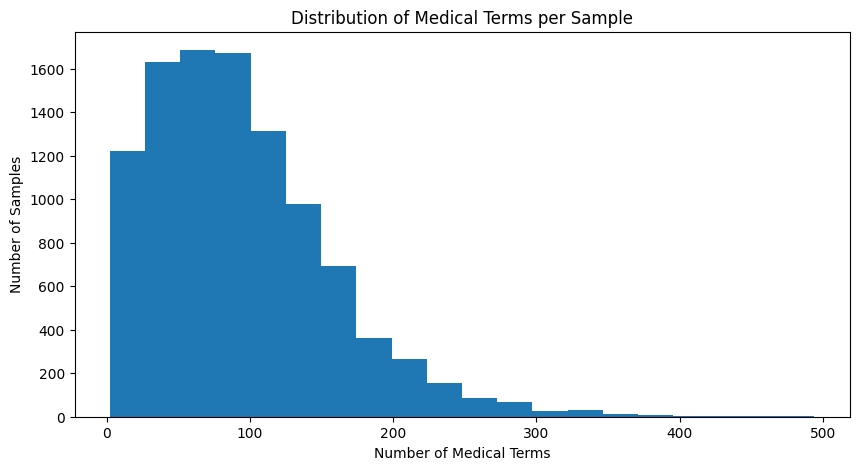

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.hist(df["medical_term_count"], bins=20)

plt.title("Distribution of Medical Terms per Sample")
plt.xlabel("Number of Medical Terms")
plt.ylabel("Number of Samples")

plt.show()

In [51]:
import ast

def ensure_list(x):
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return []
    return []

df["medical_terms_clean"] = df["medical_terms_clean"].apply(ensure_list)

In [52]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio,audio,file_exists,text,reference,sample_id,medical_term_count,medical_terms_clean
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,54.947548,0.319377,/content/drive/MyDrive/Brock_University/pidgin...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227,74,"[exercise, everytime, after, two, day, normall..."
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,53.953575,0.334655,/content/drive/MyDrive/Brock_University/pidgin...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2,106,"[daughter, wake, up, vomited, pain, hot, parac..."
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,57.647476,0.335672,/content/drive/MyDrive/Brock_University/pidgin...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4,85,"[reasons, removed, important, part, of, the, b..."
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,49.890247,0.308394,/content/drive/MyDrive/Brock_University/pidgin...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366,158,"[thirty, one, years, woman, not, head, injury,..."
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,50.834831,0.307166,/content/drive/MyDrive/Brock_University/pidgin...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166,254,"[forty, five, years, old, man, platelet, count..."


In [53]:
from collections import Counter

all_terms = [term for terms in df["medical_terms_clean"] for term in terms]

term_counts = Counter(all_terms)

top_terms = pd.DataFrame(
    term_counts.most_common(30),
    columns=["medical_term", "count"]
)

top_terms

,medical_term,count
0,pain,2393
1,two,1007
2,old,912
3,one,910
4,years,883
5,days,869
6,blood,783
7,wet,766
8,back,763
9,no,721


In [54]:
# Basic English stopwords
basic_stopwords = {
    "of", "to", "the", "and", "a", "in", "on", "for", "with"
}

# Number words
number_words = {
    "one","two","three","four","five","six","seven","eight","nine","ten",
    "twenty","thirty","hundred"
}

# Time-related words
time_words = {
    "day","days","week","weeks","month","months","year","years"
}

# Direction / generic words
generic_words = {
    "left","right","back","lower","old"
}

# Combine all
remove_words = basic_stopwords | number_words | time_words | generic_words

In [55]:
def filter_medical_terms(terms):
    if not isinstance(terms, list):
        return []

    return [t for t in terms if t not in remove_words]

df["medical_terms_clean"] = df["medical_terms_clean"].apply(filter_medical_terms)

In [56]:
from collections import Counter

all_terms = [term for terms in df["medical_terms_clean"] for term in terms]
term_counts = Counter(all_terms)

top_terms_clean = pd.DataFrame(
    term_counts.most_common(30),
    columns=["medical_term", "count"]
)

In [57]:
top_terms_clean

,medical_term,count
0,pain,2393
1,blood,783
2,wet,766
3,no,721
4,fit,655
5,normal,651
6,test,549
7,small,545
8,not,516
9,de,499


In [58]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio,audio,file_exists,text,reference,sample_id,medical_term_count,medical_terms_clean
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,54.947548,0.319377,/content/drive/MyDrive/Brock_University/pidgin...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227,74,"[exercise, everytime, after, normally]"
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,53.953575,0.334655,/content/drive/MyDrive/Brock_University/pidgin...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2,106,"[daughter, wake, up, vomited, pain, hot, parac..."
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,57.647476,0.335672,/content/drive/MyDrive/Brock_University/pidgin...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4,85,"[reasons, removed, important, part, body, exam..."
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,49.890247,0.308394,/content/drive/MyDrive/Brock_University/pidgin...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366,158,"[woman, not, head, injury, ribs, somehow, body..."
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,50.834831,0.307166,/content/drive/MyDrive/Brock_University/pidgin...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166,254,"[forty, man, platelet, count, zero, checked, h..."


In [59]:
!pip install wordcloud matplotlib

In [72]:
extra_remove_words = {
    "more", "fifteen", "forty", "few", "than", "every",
    "son", "upper", "hours", "once", "times", "fifty", "visit"
}
extra_remove_words = {
    "ago", "twelve", "hands", "over", "husband", "this", "no", "my", "after", "not", "na", "dey", "di"
}

# Combine with previous filter set
remove_words = remove_words | extra_remove_words

In [73]:
def filter_medical_terms(terms):
    if not isinstance(terms, list):
        return []

    return [t for t in terms if t not in remove_words]

df["medical_terms_clean"] = df["medical_terms_clean"].apply(filter_medical_terms)

In [74]:
from collections import Counter

all_terms = [term for terms in df["medical_terms_clean"] for term in terms]
term_counts = Counter(all_terms)

top_terms_clean = pd.DataFrame(
    term_counts.most_common(30),
    columns=["medical_term", "count"]
)

In [75]:
top_terms_clean

,medical_term,count
0,pain,2393
1,blood,783
2,wet,766
3,fit,655
4,normal,651
5,test,549
6,small,545
7,de,499
8,mg,487
9,chest,472


In [76]:
# Convert list of medical terms into text per row
df["medical_terms_text"] = df["medical_terms_clean"].apply(
    lambda terms: " ".join(terms) if isinstance(terms, list) else ""
)

In [77]:
extra_remove_words = {
    "need", "hello", "pain", "cause", "help", "hi", "hope",
    "old", "years", "just", "days", "years old", "year", "months", "ago", "like", "day", "hi",
    "value", "question", "concern", "hi", "neck", "thank", "helps", "skin", "dl", "used", "boyfrined",
    "daugther",
}

# Combine with previous filter set
remove_words = remove_words | extra_remove_words

def filter_medical_terms(terms):
    if not isinstance(terms, list):
        return []

    return [t for t in terms if t not in remove_words]

df["medical_terms_clean"] = df["medical_terms_clean"].apply(filter_medical_terms)

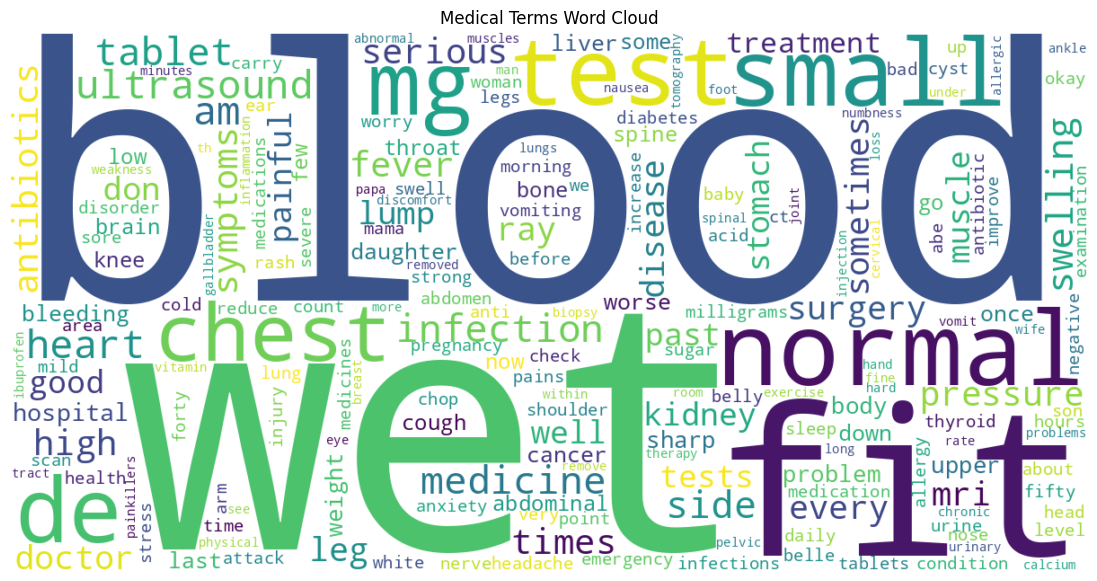

In [78]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import Counter

# Remove the word "my" from each row
df["medical_terms_clean"] = df["medical_terms_clean"].apply(
    lambda terms: [t for t in terms if t != "my"] if isinstance(terms, list) else []
)

# Flatten all medical terms
all_terms = [term for terms in df["medical_terms_clean"] for term in terms]

# Count frequencies
term_counts = Counter(all_terms)

# Generate word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    collocations=False
).generate_from_frequencies(term_counts)

# Plot
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Medical Terms Word Cloud")
plt.show()

In [ ]:
df.to_csv(base+"metadata_version2.0.csv", index=False)